# Extracting lithium from softened Smackover brine with four solvents

This notebook builds and solves a three-stage countercurrent solvent-extraction flowsheet for lithium with the IDAES
and PrOMMiS process-modeling tools, using ePC-SAFT phase and chemical equilibrium in every stage. It then compares four
solvent systems on the same synthetic softened Smackover MS-2 brine. It accompanies the solvent-comparison study of the Lithium_Extraction project.

**Runtime:** about 40 seconds. Run the cells in order, top to bottom. Each cell does one step of the simulation and
shows its result, like stepping through a process simulator.

**How to run.** Set up the environment once as described in [README.md](README.md): a conda environment with
Python 3.13, the ePC-SAFT Engine and Reaktoro, with this PrOMMiS checkout installed in it. Then start `jupyter lab` in
this folder, open this notebook and choose *Run All*. To run it without opening it:

```sh
jupyter nbconvert --to notebook --execute --inplace lithium_solvent_comparison.ipynb
```
**As an app.** `voila lithium_solvent_comparison.ipynb` (after `pip install voila`) serves this notebook as a web page that shows only the text, widgets and results, with the code hidden; it runs every cell when the page opens.

The helper functions called below live in `tutorial_tools/` in this folder. Each takes the model `m` and does one
job that would otherwise bury the flowsheet steps: writing the equilibrium constraints, the organic feed, the
starting point, the figures and the checks. The Lithium model code they call is in
`lithium_extraction/` and `analyses/`.

## Learning outcomes

- Build a countercurrent solvent-extraction flowsheet from the PrOMMiS `SolventExtraction` unit model
- Close each stage with ePC-SAFT chemical and phase equilibrium, called by the solver as an external function
- Specify a design, check the degrees of freedom, initialize and solve with IPOPT
- See how the ePC-SAFT Engine works inside the IDAES/PrOMMiS model: called by the solver, with exact derivatives
- Optimize the design with the same model, and explore other designs with widgets
- Compare lithium recovery, Li/Na selectivity and the sodium carried by four solvent systems
- Check every reproduced number against the study's retained results

## Problem statement

Produced water from oil and gas wells can carry lithium. Smackover Formation brine in southern Arkansas is one
example, and it holds far more sodium than lithium: in sample MS-2 there are about **115 sodium ions for every
lithium ion**. A useful extraction solvent must take up lithium while leaving most of that sodium behind.

**Solvent extraction** mixes the brine (the *aqueous* phase) with an oil-like liquid (the *organic* phase) that holds
an extractant. Lithium moves into the organic phase, and the two liquids then separate. A **stage** is one
mix-and-settle step. In a **countercurrent** cascade the brine flows from stage 1 to stage $N$ while fresh organic
enters at stage $N$ and flows back toward stage 1, so the brine meets the cleanest organic just before it leaves.

**The question:** on the same softened MS-2 feed, how much lithium can each of four solvent systems recover, and how
much sodium comes along? This notebook answers it for three stages at each system's retained maximum-recovery design.

| System | What the extractant does |
|---|---|
| Acid-form HBTA/TOPO | HBTA gives up a proton (H⁺) for Li⁺; TOPO completes the lithium complex in the organic phase |
| Sodium-saponified HBTA/TOPO | HBTA is first converted to its sodium form with NaOH, so it trades Na⁺ for Li⁺ instead of releasing acid |
| D2EHDTPA/BuPhen | a sodium-form dithiophosphate site trades Na⁺ for Li⁺; BuPhen binds the lithium |
| TBAC:DA/TOPO deep eutectic solvent | the solvent takes up Li⁺ together with a chloride ion |

### Glossary

| Term | Meaning |
|---|---|
| MS-2 | USGS produced-water sample AR2022, well MSPU 4-W1, Magnolia Smackover Production Unit, Arkansas |
| softened | calcium, magnesium, strontium and barium assumed removed beforehand, with no lithium lost |
| O/A | organic-to-aqueous volume ratio |
| HBTA, TOPO | benzoyltrifluoroacetone (the acidic extractant) and tri-*n*-octylphosphine oxide (a neutral co-extractant) |
| D2EHDTPA, BuPhen | bis(2-ethylhexyl)dithiophosphoric acid and a substituted phenanthroline that binds lithium |
| TBAC:DA, DES | tetrabutylammonium chloride : decanoic acid, a deep eutectic solvent |
| ePC-SAFT | electrolyte perturbed-chain statistical associating fluid theory, the thermodynamic model |
| Engine | the project's pinned ePC-SAFT equilibrium library |
| raffinate | the brine leaving the last stage |

## Step 1: Import the tools

The IDAES and PrOMMiS pieces of the flowsheet, the stage property packages, and the tutorial helpers.

In [1]:
from idaes.core import FlowDirection, FlowsheetBlock
from idaes.core.util.model_statistics import degrees_of_freedom
from prommis.solvent_extraction.solvent_extraction import SolventExtraction
from pyomo.environ import ConcreteModel, value

import tutorial_tools as tools
from tutorial_tools import solvent_comparison as sc
from lithium_extraction.prototypes.produced_water_sx_prototype.stage import ExtentReactions, MolarFlowParameters

In [2]:
tools.versions()

,version
ePC-SAFT Engine,1.2.0 (source commit 4cb87490)
IDAES,2.13.0
PrOMMiS,1.1.0+gc36e5836c
Pyomo,6.10.1


The flowsheet we will build: three countercurrent stages.

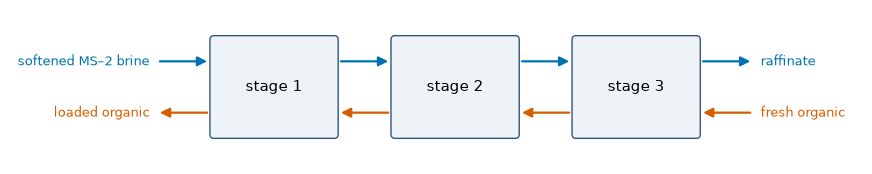

In [3]:
sc.draw_cascade()

## Step 2: Inputs

### 2.1 The feed: synthetic softened MS-2

All four systems start from the same brine, per litre of feed at 298.15 K and 101 325 Pa:

- Li, Na and K from the printed USGS MS-2 analysis (168, 64 100 and 2 300 mg/L);
- calcium, magnesium, strontium and barium removed with their chloride, as if softened upstream with no lithium lost;
- acid at pH 5.77, $c_{H^+} = 10^{-5.77}$ mol/L, with equal chloride, and 55.508 mol of water;
- chloride set by charge balance, $\sum_i z_i c_i = 0$.

K and an equal amount of chloride pass through unchanged; the equilibrium model leaves them out. Each solvent then
conditions its own inlet (saponification adds organic sodium; the DES adds aqueous ammonia).

In [4]:
sc.feed_table()

,mol per L feed,mg/L,"model feed, HBTA/TOPO and DES (mol/L)","model feed, D2EHDTPA/BuPhen (mol/L)"
Li,0.0242,168,0.0242,0.0242
Na,2.79,"64,100",2.79,2.79
K,0.0588,"2,300",NaN,NaN
water,55.5,NaN,55.5,55.5
H,1.7e-06,0.00171,1.7e-06,NaN
Cl,2.87,"101,794",2.81,2.81
Mg,0,0,NaN,NaN
Ca,0,0,NaN,NaN
Sr,0,0,NaN,NaN
Ba,0,0,NaN,NaN


### 2.2 The designs

The study optimized each system for **maximum lithium recovery** at each stage count from 1 to 5. Here we take the
**three-stage** optimum of every system from its retained results. The design variables are, in physical units:

- **HBTA/TOPO** (both forms): O/A, extractant concentration $c$ (mol per litre of organic, equal HBTA and TOPO) and the
  saponified fraction $r_{Na}$ (0 for the acid form);
- **D2EHDTPA/BuPhen**: O/A, BuPhen concentration $B$ (mol/L organic) and the exchange-site supply $S$ (sodium-form
  sites per mol of feed lithium);
- **DES**: total aqueous ammonia nitrogen (mol per litre of feed) and the TOPO mass fraction.

Most optima sit on a bound: both HBTA/TOPO forms are at O/A = 3 and at their upper extractant bound, $c$ = 0.3 mol/L
for the acid form and 0.4 mol/L for the sodium-saponified form.

In [5]:
sc.designs()

value
system                      design variable                              
Acid HBTA/TOPO              O/A                                         3
                            c, HBTA and TOPO each (mol/L organic)     0.3
                            r_Na, sodium-form fraction of HBTA          0
Sodium-saponified HBTA/TOPO O/A                                         3
                            c, HBTA and TOPO each (mol/L organic)     0.4
                            r_Na, sodium-form fraction of HBTA      0.995
D2EHDTPA/BuPhen             O/A                                      1.82
                            B, BuPhen (mol/L organic)             > 0.999
                            S, sodium-form sites per mol feed Li      1.5
TBAC:DA/TOPO DES            ammonia nitrogen (mol per L feed)     0.00512
                            TOPO mass fraction of the organic       0.325

## Step 3: The chemistry

Each stage reaches **chemical and phase equilibrium**. For the acid-form HBTA/TOPO system (HBTA written HA, TOPO
written T) two reactions move lithium and sodium into the organic, each releasing a proton:

$$
\mathrm{M^+_{(aq)} + HA_{(org)} + T_{(org)} \;\rightleftharpoons\; MA{\cdot}T_{(org)} + H^+_{(aq)}},
\qquad \mathrm{M = Li,\ Na}
$$

The other systems exchange sodium rather than a proton, or take up chloride:

| System | Lithium uptake |
|---|---|
| Sodium-saponified HBTA/TOPO | $\mathrm{Li^+_{(aq)} + NaA{\cdot}T_{(org)} \rightleftharpoons LiA{\cdot}T_{(org)} + Na^+_{(aq)}}$, with the acid reactions above and HBTA dissolving as $\mathrm{HA_{(org)} \rightleftharpoons H^+_{(aq)} + A^-_{(aq)}}$ |
| D2EHDTPA/BuPhen (A = dithiophosphate, B = BuPhen) | $\mathrm{Li^+_{(aq)} + NaA_{(org)} + 2B_{(org)} \rightleftharpoons LiA{\cdot}2B_{(org)} + Na^+_{(aq)}}$ |
| TBAC:DA/TOPO DES (D = one third of a solvent formula unit) | $\mathrm{M^+_{(aq)} + Cl^-_{(aq)} + 3D_{(org)} \rightleftharpoons 3\,(MCl{\cdot}D)_{(org)}}$ |

ePC-SAFT supplies the activity $a$ of every species in each liquid. Reaction $r$ is at equilibrium when

$$
\sum_{p,i} \nu_{r,pi} \ln a_{pi} - \ln K_r = 0 ,
$$

where $\nu_{r,pi}$ is the stoichiometric coefficient of species $i$ in phase $p$ and $K_r$ the fitted equilibrium
constant. Because acid-form HBTA releases one H⁺ for every Li⁺ it extracts, the brine grows more acidic from stage to
stage and holds extraction back. That is the main difference between the acid form and the other three systems.

We build the acid-form system by hand. `sc.acid_hbta_topo()` returns its compiled Engine record (species, conserved
totals and the equilibrium library), the organic reference state, and the brine feed in mol per litre.

In [6]:
chemistry, reference, brine = sc.acid_hbta_topo()
dict(zip(('aqueous species', 'organic species'), chemistry.supports))

{'aqueous species': ('water',
  'lithium-cation',
  'sodium-cation',
  'hydrogen-cation',
  'chloride-anion'),
 'organic species': ('diluent',
  'hbta',
  'topo',
  'lithium-carrier',
  'sodium-carrier')}

## Step 4: Build the flowsheet

### 4.1 The model and flowsheet

As in every IDAES model: a Pyomo `ConcreteModel` holding a steady-state `FlowsheetBlock`.

In [7]:
m = ConcreteModel()
m.fs = FlowsheetBlock(dynamic=False)

### 4.2 Property packages

One package per phase. Its state is the molar flow of each species, in mol/h at 1 L/h of brine, so every flow equals
mol per litre of feed.

In [8]:
m.fs.aqueous_properties = MolarFlowParameters(phase='aqueous', species=chemistry.supports[0])
m.fs.organic_properties = MolarFlowParameters(phase='organic', species=chemistry.supports[1])

### 4.3 Reaction package: transfer extents

In stage $k$ the amounts leaving, $\mathbf n^{out}_k$, are the amounts entering, $\mathbf n^{in}_k$ (brine from stage
$k-1$, organic from stage $k+1$), plus the change made by the extents $\boldsymbol\xi_k$:

$$
\mathbf n^{out}_k = \mathbf n^{in}_k + \mathbf N\,\boldsymbol\xi_k ,
\qquad \mathbf C\,\mathbf N = \mathbf 0 .
$$

Each row of $\mathbf C$ counts one conserved total (Li, Na, exchangeable H, BTA, TOPO). `extent_stoichiometry` picks
one extent per independent species and builds $\mathbf N$ from the null space of $\mathbf C$, so no extent can create
or destroy lithium or any other total.

In [9]:
m.fs.extents = ExtentReactions(stoichiometry=tools.extent_stoichiometry(chemistry))

### 4.4 The extraction unit

One PrOMMiS `SolventExtraction` unit with three stages: brine flows forward from stage 1, organic backward from
stage 3.

In [10]:
m.fs.extraction = SolventExtraction(
    number_of_finite_elements=3,
    heterogeneous_reaction_package=m.fs.extents,
    aqueous_stream={'property_package': m.fs.aqueous_properties, 'flow_direction': FlowDirection.forward},
    organic_stream={'property_package': m.fs.organic_properties, 'flow_direction': FlowDirection.backward},
)
tools.label_streams(m)
degrees_of_freedom(m)

25

`label_streams` adds short names: `m.fs.boundary[s]` is the feed of species $s$ (brine or fresh organic) and
`m.fs.stage[k].outlet[s]` the amount of $s$ leaving stage $k$. Nothing yet says *how much* moves between the phases,
so many degrees of freedom remain open.

### 4.5 Equilibrium in every stage

The Engine returns the equilibrium amounts leaving a stage from what enters it,

$$
n^{out}_{s,k} = \mathcal E_s\!\left(\mathbf n^{in}_k;\ T, P\right),
$$

as a Pyomo `ExternalFunction` with exact first and second derivatives, one equation per independent species.

In [11]:
tools.add_stage_equilibrium(m, [chemistry] * 3)
degrees_of_freedom(m)

10

### 4.6 Fix the brine feed

In [12]:
for species, amount in brine.items():
    m.fs.boundary[species].fix(amount)
degrees_of_freedom(m)

5

### 4.7 The design and the fresh organic

The acid-form design from Step 2 (O/A, $c$ and $r_{Na} = 0$) is fixed, and the fresh organic is written in terms of
it. Per litre of brine it carries

$$
n_{HBTA} = n_{TOPO} = \mathrm{O/A}\cdot c\,(1-r_{Na}), \qquad
n_{NaA{\cdot}T} = \mathrm{O/A}\cdot c\,r_{Na}, \qquad
n_{LiA{\cdot}T} = 0 ,
$$

with diluent filling the rest of the O/A litres of organic. As in the study, the lithium complex leaving any stage may
not exceed 72 % of the extractant circulated, $n_{LiA{\cdot}T,k} \le 0.72\,\mathrm{O/A}\cdot c$. The model is now square.

In [13]:
start, design = sc.design('acid_A')
fixed = sc.add_design(m, design, reference)
assert degrees_of_freedom(m) == 0
fixed

,fixed value
O/A,3
"c, HBTA and TOPO each (mol/L organic)",0.3
"r_Na, sodium-form fraction of HBTA",0


## Step 5: Initialize

IPOPT needs a starting point close to the answer. `sc.initialize` first sets the organic feed from the design, then
runs a **stage-by-stage countercurrent calculation** that solves one stage at a time with the Engine, sweeping from
stage 1 to stage 3 until the organic leaving each stage stops changing. It loads that profile into every stage and sets
the extents from the balances, so every equation except equilibrium starts satisfied.

The lithium left in the brine at the start, in mol per litre of feed:

In [14]:
sc.initialize(m, brine)
tools.stage_profile(m, ['lithium-cation'])

stage,1,2,3
lithium-cation,0.0184,0.0151,0.0118


## Step 6: Solve

IPOPT solves all three stages together with exact second derivatives and a tolerance of $10^{-11}$; the solver's
optimality conditions are then checked from its log (each should be near zero). The design stays fixed, so this is a
simulation, not an optimization.

In [15]:
sc.solve(m, 'acid_hbta_topo')['kkt']

{'stationarity': 0.0,
 'complementarity': 0.0,
 'feasibility': 9.99999999987899e-15,
 'multiplier_sign': 0.0}

## Step 7: Results for the acid form

The unit model's `report()` shows the streams entering and leaving the cascade (mol per litre of feed).

In [16]:
m.fs.extraction.report()


Unit : fs.extraction                                                       Time: 0.0
------------------------------------------------------------------------------------
    Unit Performance


------------------------------------------------------------------------------------
    Stream Table
                                      Units       aqueous Inlet  aqueous Outlet  organic Inlet  organic Outlet
    flow_mol_comp water            dimensionless       55.508         55.508               -              -   
    flow_mol_comp lithium-cation   dimensionless     0.024204       0.011827               -              -   
    flow_mol_comp sodium-cation    dimensionless       2.7882         2.7482               -              -   
    flow_mol_comp hydrogen-cation  dimensionless   1.6982e-06       0.052409               -              -   
    flow_mol_comp chloride-anion   dimensionless       2.8124         2.8124               -              -   
    flow_mol_comp diluent          dim

Inside the cascade, the lithium left in the brine falls only slowly from stage to stage while the acid builds up:
every Li⁺ extracted releases an H⁺. Lithium recovery is

$$
E_{Li} = \frac{n_{Li,aq,in} - n_{Li,aq,N}}{n_{Li,aq,in}} .
$$

In [17]:
recovery = 1 - value(m.fs.stage[3].outlet['lithium-cation']) / brine['lithium-cation']
print(f'Lithium recovery: {100 * recovery:.2f} %')
tools.stage_profile(m, ['lithium-cation', 'sodium-cation', 'hydrogen-cation', 'lithium-carrier', 'sodium-carrier'])

Lithium recovery: 51.14 %


stage,1,2,3
lithium-cation,0.0184,0.0151,0.0118
sodium-cation,2.77,2.76,2.75
hydrogen-cation,0.0201,0.0327,0.0524
lithium-carrier,0.0124,0.00657,0.0033
sodium-carrier,0.04,0.0257,0.0164


## Step 8: How the ePC-SAFT Engine works inside the flowsheet

The Engine is the project's ePC-SAFT equilibrium library, compiled for this chemistry. IDAES and PrOMMiS see it as an
ordinary part of the Pyomo model, so the same flowsheet can be simulated, optimized and connected to other units.

### 8.1 One equation of the model

Each Engine-closed outlet is one Pyomo constraint whose right-hand side is the Engine, called on the variables that
enter the stage. Printed, it reads as an ordinary model equation: an outlet flow of the PrOMMiS unit equals
`engine(...)` of the inlet flows, followed by the compiled record and the species' phase and position in it.

In [18]:
equation = m.fs.stage[1].equilibrium[next(iter(m.fs.stage[1].equilibrium))]
print(equation.expr.to_string()[:600], '...')

fs.extraction.mscontactor.aqueous[0.0,1].flow_mol_comp[water]  ==  engine(fs.extraction.mscontactor.organic[0.0,2].flow_mol_comp[diluent], fs.extraction.mscontactor.aqueous_inlet_state[0.0].flow_mol_comp[lithium-cation], fs.extraction.mscontactor.aqueous_inlet_state[0.0].flow_mol_comp[sodium-cation], fs.extraction.mscontactor.aqueous_inlet_state[0.0].flow_mol_comp[hydrogen-cation], fs.extraction.mscontactor.organic[0.0,2].flow_mol_comp[hbta], fs.extraction.mscontactor.organic[0.0,2].flow_mol_comp[sodium-carrier], fs.extraction.mscontactor.organic[0.0,2].flow_mol_comp[lithium-carrier], '26:epcs ...


### 8.2 Calling the Engine directly

The Engine can also be called outside the solver. Called on the amounts entering stage 1 at the solution, it returns
the same outlets the flowsheet holds: the solved model and a standalone equilibrium calculation agree.

In [19]:
tools.engine_check(m, 1)

epcsaft_equilibrium prepared record 1


,direct Engine call (mol/L),flowsheet outlet (mol/L),difference (mol/L)
leaving stage 1,,,
water,55.5,55.5,7.11e-15
chloride-anion,2.81,2.81,4.44e-16
diluent,13,13,3.55e-15
lithium-carrier,0.0124,0.0124,8.4e-16
sodium-carrier,0.04,0.04,1.25e-16


### 8.3 Exact derivatives

IPOPT needs the derivatives of every equation. The Engine returns exact first and second derivatives with each value,
$\partial n^{out}_s / \partial n^{in}_q$ and $\partial^2 n^{out}_s / \partial n^{in}_q \partial n^{in}_r$, by
differentiating the ePC-SAFT equilibrium conditions themselves, not by finite differences. The table compares the
exact first derivatives of the lithium complex leaving stage 1 with central finite differences (step $10^{-6}$ of
each input, and at least $10^{-9}$ mol/L); they agree to a few parts per million or better, the accuracy of the
finite differences. These derivatives are what let IPOPT converge the
whole flowsheet in a few iterations, and what make the optimization in Step 12 possible.

In [20]:
tools.engine_derivatives(m, 1, 'lithium-carrier')

,exact (Engine),finite difference,relative difference
"d n(out, lithium-carrier) / d n(in)",,,
entering diluent,-0.000168,-0.000168,1.16e-07
entering lithium-cation,0.358,0.358,1.6e-09
entering sodium-cation,-0.000758,-0.000758,3.74e-08
entering hydrogen-cation,-0.106,-0.106,9.4e-07
entering hbta,0.00511,0.00511,4.95e-08
entering sodium-carrier,0.11,0.11,4.81e-08
entering lithium-carrier,0.469,0.469,1.1e-07


## Step 9: All four solvent systems

The other three systems add their own chemistry (sodium-form organic, BuPhen and exchange sites, or the DES ammonia
conditioning) to the same stage structure. `sc.solve_all` builds and solves all four with the study's own builder, at
their retained designs, and keeps a design only if:

- IPOPT converged with its optimality conditions inside their limits;
- every stage, re-solved on its own with the Engine from its solved inlet, matches the flowsheet within $10^{-9}$ mol
  per litre of feed;
- every conserved total balances within $10^{-9}$ mol;
- the system's physical check on the raffinate passes.

A design that fails is reported in the table rather than stopping the notebook.

In [21]:
solved, status = sc.solve_all()
status

epcsaft_equilibrium prepared record 2


epcsaft_equilibrium prepared record 3


epcsaft_equilibrium prepared record 4


,solved,largest balance error (mol/L),largest stage re-solve difference (mol/L),wall time (s)
system,,,,
Acid HBTA/TOPO,True,1.01e-14,2.13e-14,1.6
Sodium-saponified HBTA/TOPO,True,4.44e-16,2.13e-14,5
D2EHDTPA/BuPhen,True,4.58e-16,7.11e-15,1.3
TBAC:DA/TOPO DES,True,2.01e-14,7.82e-14,4.1


The acid-form flowsheet built by hand above and the one built by the study's builder agree. The largest difference
in any stage outlet, in mol per litre of feed (the cell stops if it exceeds $10^{-9}$):

In [22]:
sc.matches_repository_build(m, solved)

0.0

## Step 10: Compare the four designs

For stage 1, where the brine enters, the distribution ratio of a metal, the Li/Na selectivity and the sodium share of
the loaded organic are

$$
D_M = \frac{c_{M,org,1}}{c_{M,aq,1}}, \qquad
\beta = \frac{D_{Li}}{D_{Na}}, \qquad
x_{Na,org} = \frac{n_{Na,org,1}}{n_{Li,org,1} + n_{Na,org,1}} ,
$$

and the net sodium moved into the organic, per m³ of feed, is $\Delta n_{Na,org} = 1000\,(n_{Na,org,1} - n_{Na,org,in})$, with the amounts in mol per litre of feed
(negative when the organic releases sodium). $n_{Li,aq,N}$ is the lithium left in the raffinate, leaving stage
$N = 3$. When it falls below
the declared comparison amount, $10^{-9}$ mol/L, the recovery cannot be told apart from 1 and is shown as $\approx 1$.

In [23]:
sc.headline(solved)

,Acid HBTA/TOPO,Sodium-saponified HBTA/TOPO,D2EHDTPA/BuPhen,TBAC:DA/TOPO DES
$E_{Li}$,0.511,> 0.999,0.997,$\approx 1$
$\beta = D_{Li}/D_{Na}$,46.6,166,753,370
"$x_{Na,org}$",0.764,0.979,0.336,0.9
"$\Delta n_{Na,org}$ (mol/m$^3$)",40,-78.9,-24.1,218
"$n_{Li,aq,N}$ (mol/L)",0.0118,7.91e-08,8.27e-05,$< 10^{-9}$


**Reading the table.**

- **Acid-form HBTA/TOPO recovers about half the lithium (51 %).** Every Li⁺ it extracts releases an H⁺, and nothing
  neutralizes that acid, so the rising acidity holds back further extraction.
- **The two sodium-form systems and the DES recover almost all the lithium in three stages.** The sodium-form
  exchangers release Na⁺ rather than acid, and the DES takes chloride along with each metal ion.
- **High recovery does not mean a lithium-rich organic.** About 115 Na come in for every Li. Even with stage-1
  selectivities of 166 to 753, the organic leaving the sodium-saponified HBTA/TOPO cascade is 98 % sodium and the DES
  organic 90 %. D2EHDTPA/BuPhen is the exception, at 34 % sodium.
- **Net sodium separates two cases.** The sodium-form exchangers enter loaded with their own sodium and give some back,
  so their net transfer is negative; the acid form and the DES take sodium from the brine.

### Stage profiles

The brine enters at stage 1 and leaves at stage 3; fresh organic enters at stage 3 and leaves, loaded, at stage 1.
Points are the solved stage outlets; nothing is interpolated between stages. DES organic amounts are counted in
formula units, and a selectivity whose lithium amount is below the comparison amount is left blank.

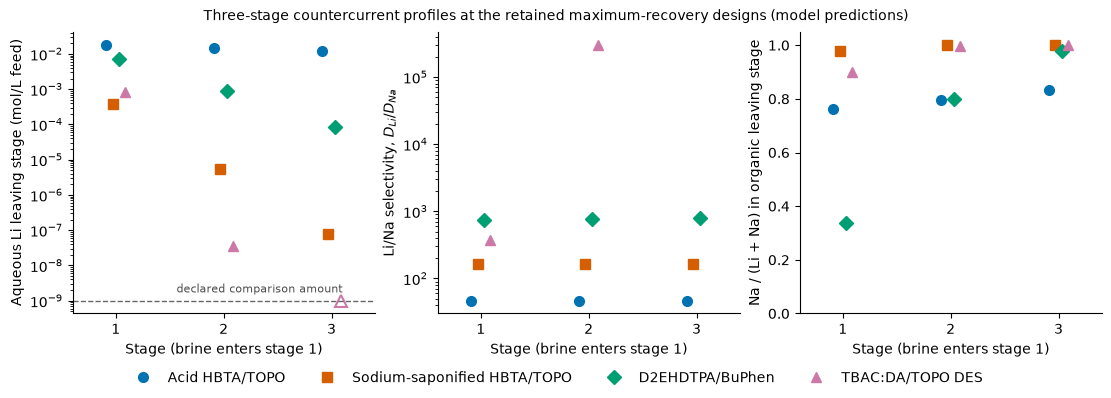

In [24]:
sc.plot_profiles(sc.profiles(solved))

**Reading the figure.**

- **Left.** Lithium left in the brine falls about 68-fold per stage for sodium-saponified HBTA/TOPO and 8- to 11-fold
  for D2EHDTPA/BuPhen, but only 1.2- to 1.3-fold for the acid form, because acid builds up. By stage 3 the DES brine
  lithium is below the comparison amount (open marker on the dashed line), so its recovery is indistinguishable from
  complete.
- **Middle.** Selectivity barely changes from stage to stage for both HBTA/TOPO forms and rises slightly for
  D2EHDTPA/BuPhen (753 to 789). For the DES it rises by about three orders of magnitude from stage 1 to stage 2.
- **Right.** Every system except the acid form leaves stage 3 with an organic that is nearly all sodium. Lithium is
  picked up toward stage 1. D2EHDTPA/BuPhen ends mostly lithium, while sodium-saponified HBTA/TOPO stays 98 % sodium:
  it circulates about 1.2 mol of sodium-form HBTA per litre of feed against 0.024 mol of lithium.

## Step 11: Check against the study's retained results

This step shows the notebook still reproduces the study. For every system it recomputes **every number in the
retained results row** (`optimum_quantities.csv` and the matching row of `pmax_comparison.csv`) and compares **every
stage outlet amount** with the retained solve record, both the optimizer's solve and its fixed-design replay. The
tolerances are those declared for replaying the retained states:

- amounts (raffinate Li and stage outlets): $|a-b| \le 10^{-9}$ mol per litre of feed;
- every other quantity: $\dfrac{|a-b|}{\max(|a|, |b|, 10^{-6})} \le 10^{-6}$.

The figure puts every comparison on one scale, its difference divided by its tolerance: a point below the red line
is within tolerance, and a difference of $10^{-12}$ of the tolerance or less (exact agreement included)
sits on the bottom line. Text fields, compared for equality, are counted in the
table but not drawn. The cell stops with an error if any comparison fails; `comparisons` holds every line.

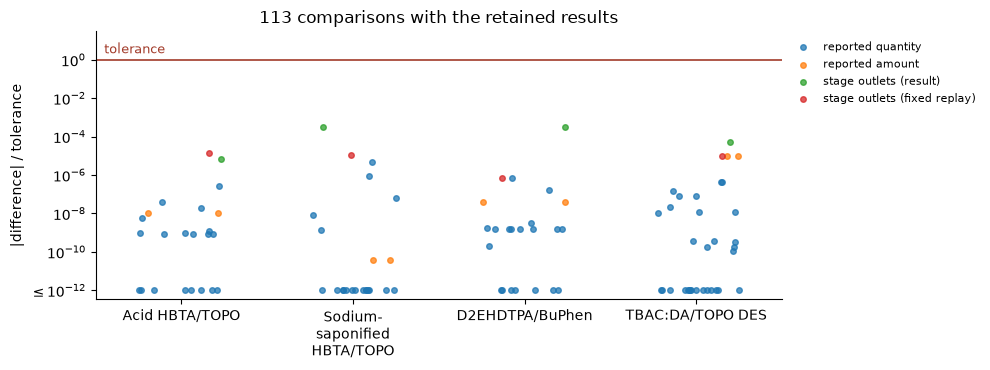

,comparisons,largest difference / tolerance,all within tolerance
Acid HBTA/TOPO,25,1.4e-05,✓
Sodium-saponified HBTA/TOPO,25,3.2e-04,✓
D2EHDTPA/BuPhen,25,3.1e-04,✓
TBAC:DA/TOPO DES,38,5.0e-05,✓


In [25]:
summary, comparisons = sc.check_retained(solved)
summary

## Step 12: Optimize the acid-form design

The same model optimizes. We move the acid-form design to a weaker starting point, O/A = 1 and $c$ = 0.1 mol/L, and
solve it as a simulation: the recovery drops. Then the two design variables are released inside the study's bounds,
$0.5 \le \mathrm{O/A} \le 3$ and $0.05 \le c \le 0.30$ mol/L, and IPOPT maximizes lithium recovery by minimizing the
lithium left in the raffinate,

$$
\min_{\mathrm{O/A},\,c}\; n_{Li,aq,3}
\quad \text{subject to the flowsheet, the Engine equilibrium in every stage and}\quad
n_{LiA{\cdot}T,k} \le 0.72\,\mathrm{O/A}\cdot c .
$$

In [26]:
design = m.fs.design
design.organic_to_aqueous_ratio.fix(1.)
design.extractant_mol_l.fix(.1)
sc.initialize(m, brine)
sc.solve(m, 'acid_hbta_topo_start')
starting = {'O/A': 1., 'c (mol/L organic)': .1,
            '$E_{Li}$': 1 - value(m.fs.stage[3].outlet['lithium-cation']) / brine['lithium-cation']}
starting

{'O/A': 1.0, 'c (mol/L organic)': 0.1, '$E_{Li}$': 0.11743964004397289}

Release the design and replace the constant objective with the raffinate lithium. Two degrees of freedom open:

In [27]:
from pyomo.environ import Objective

design.organic_to_aqueous_ratio.unfix()
design.extractant_mol_l.unfix()
m.feasibility.deactivate()
m.raffinate_lithium = Objective(expr=m.fs.stage[3].outlet['lithium-cation'])
degrees_of_freedom(m)

2

In [28]:
sc.solve(m, 'acid_hbta_topo_optimize')['kkt']

{'stationarity': 7.40997541104349e-13,
 'complementarity': 1.0000934731638337e-09,
 'feasibility': 3.531619441332623e-13,
 'multiplier_sign': 0.0}

The optimizer drives both design variables to their upper bounds and recovers the study's retained optimum: more
organic and more extractant per litre of brine both take up more lithium, and nothing in this extraction-only problem
penalizes them. IPOPT's interior-point method stops a few $10^{-7}$ inside the bounds, so the design and the
recovery agree with the retained optimum to about that relative order.

In [29]:
sc.optimum_table(m, brine, starting)

,starting design,optimized here,retained optimum,relative difference
O/A,1,3,3,2.17e-07
c (mol/L organic),0.1,0.3,0.3,1.11e-07
$E_{Li}$,0.117,0.511,0.511,1.62e-07


## Step 13: Explore other designs

Pick a solvent system, the number of stages and its design with the widgets, then run the cell below them. Each run
builds and solves that design with the study's builder and adds it to the comparison; the sliders start at the
system's retained three-stage maximum-recovery design and stay inside the study's bounds. A design that does not
solve, or fails a check, is listed with the reason. Each solve takes a few seconds.

| Slider | Meaning |
|---|---|
| O/A | organic-to-aqueous volume ratio |
| $c$ | HBTA and TOPO, each, in mol per litre of organic |
| $r_{Na}$ | fraction of HBTA in sodium form |
| $B$, $S$ | BuPhen in mol per litre of organic; sodium-form sites per mol of feed lithium |
| ammonia nitrogen, TOPO mass fraction | the DES conditioning and organic composition |

Widgets show only in a running notebook opened with the command in "How to run" at the top.

In [30]:
designs = sc.DesignOptions()
designs

DesignOptions(children=(Dropdown(description='solvent system', layout=Layout(width='560px'), options=(('Acid H…

In [31]:
sc.run_design(designs)

,system,stages,design,$E_{Li}$,$\beta = D_{Li}/D_{Na}$,"$x_{Na,org}$","$\Delta n_{Na,org}$ (mol/m$^3$)","$n_{Li,aq,N}$ (mol/L)"
0,Acid HBTA/TOPO,3,"O/A = 3, c = 0.3",0.511,46.6,0.764,40,0.0118


Every design solved so far: recovery against the sodium share of the loaded organic, the trade-off Step 10 describes.
The two designs below start the comparison: the acid form at O/A = 2 and the D2EHDTPA/BuPhen design with one stage.

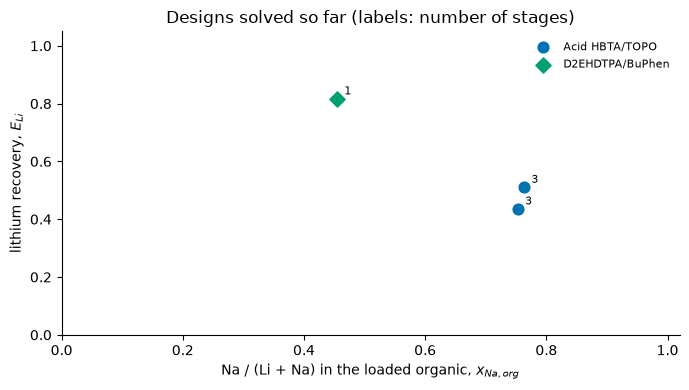

,system,stages,design,$E_{Li}$,$\beta = D_{Li}/D_{Na}$,"$x_{Na,org}$","$\Delta n_{Na,org}$ (mol/m$^3$)","$n_{Li,aq,N}$ (mol/L)"
0,Acid HBTA/TOPO,3,"O/A = 3, c = 0.3",0.511,46.6,0.764,40,0.0118
1,Acid HBTA/TOPO,3,"O/A = 2, c = 0.3",0.437,46.6,0.753,32.3,0.0136
2,D2EHDTPA/BuPhen,1,"O/A = 1.82, B = > 0.999, S = 1.5",0.817,760,0.455,-19.8,0.00442


In [32]:
designs.system.value, designs.stages.value = 'acid_A', 3
designs.sliders.children[0].value = 2.
sc.run_design(designs)
designs.system.value, designs.stages.value = 'D2Figiel', 1
sc.run_design(designs)
sc.compare_designs()

## What the numbers mean, and their limits

**What they are.** These are **model predictions with numerical verification**. The flowsheet reproduces the
study's retained results at their retained optimum designs, and every stage passes an independent equilibrium check.
That shows the calculation is solved correctly and reproducibly. It does **not** show the predictions are physically
right: no MS-2 extraction was measured, and the study adds no laboratory data. From the starting point used here the
fixed-design solves reproduce the retained designs; that does not prove the equations have only one solution.

**Limits that matter for interpretation**

- **Synthetic feed.** Softening is assumed ideal (all Ca, Mg, Sr and Ba removed with no lithium loss); no softening
  process is modeled. K is carried through but left out of the equilibrium.
- **Calibration differs by system.** Each chemistry is fitted to its own source data. The acid form misses much of its
  source distribution behavior; the saponified form misses the measured final pH; D2EHDTPA/BuPhen lacks an independent
  Li/Na-only test and its ion basis is provisional for mixed lithium brines; the DES mechanism is not identified by the
  data, so its predictions are extrapolated.
- **Different solvent amounts.** O/A, extractant concentrations and the DES mass ratio differ, so recoveries are
  compared at each system's own best design, not at equal solvent use.
- **Extraction only.** No scrub, strip, solvent regeneration, cost or product purity is calculated here (see the
  produced-water process notebook, `lithium_produced_water_process.ipynb`).
- **Not a recommendation.** The study compares conditional predictions; it does not select a solvent.

**What is not rerun here.** Only the four three-stage maximum-recovery designs. The other stage counts, the
minimum-ratio designs and the variant systems come from the same code and are covered by the retained
replay records of the Lithium_Extraction project. Step 12 reruns the acid-form optimization from one starting point; the other systems'
optimizations (free design variables and three starting points each) are not rerun. For the full
evidence, see the study's analysis notebook and manuscript in the Lithium_Extraction project.